# 01 · ภาพรวมโปรเจกต์ Sign Language Recognition (ช่วงที่ 1)

> **เป้าหมายของ notebook นี้:** อธิบาย pipeline ทั้งหมดของโปรเจกต์ได้ด้วยคำพูดของตัวเอง และเห็นด้วยตาว่า *landmarks*, *normalize*, *sequence*, *data leakage* คืออะไร ก่อนจะลงไปเรียนรายละเอียดใน notebook 02-04

**เวลาที่ใช้:** ~30-40 นาที  |  **ต้องใช้:** numpy, matplotlib, scikit-learn (ไม่ต้องใช้กล้อง ไม่ต้องใช้ GPU)

### โครงของ notebook
| ส่วน | หัวข้อ |
|---|---|
| 1 | Learning goal + แผนที่ความเชื่อมโยงของทุกแนวคิด |
| 2 | Pipeline ทั้งระบบ (diagram) |
| 3 | Landmarks: คอมพิวเตอร์ "เห็น" มือเป็นตัวเลข |
| 4 | Normalize: ทำไมต้องจัดพิกัดก่อนฝึก |
| 5 | Sequence: ทำไมต้องใช้ LSTM/GRU |
| 6 | Data leakage: ทำไมต้องแบ่ง train/test ตามผู้แสดง |
| 7 | ศัพท์ที่ต้องรู้ + สิ่งที่อยู่นอกขอบเขต + resources |

## 1. Learning goal และแผนที่ความเชื่อมโยง

คอมพิวเตอร์ **ไม่ได้เห็นมือเหมือนคน** มันได้รับแค่ตัวเลข (พิกเซล) การทำโปรเจกต์นี้คือการหาวิธีเปลี่ยน "ตัวเลขของภาพ" ให้เป็น "ความหมายของคำภาษามือ"

สิ่งที่เธอจดไว้ในโน้ต (overfit, loss curve, backbone, CNN, ViT, YOLO pose, baseline, TTS, grammar, ML ทั้งหลาย) ทุกอย่างเกี่ยวกับโปรเจกต์นี้ แต่ **ไม่ได้อยู่ระดับความสำคัญเท่ากัน** ตารางนี้บอกว่าแต่ละอันอยู่ตรงไหน:

| แนวคิด | บทบาทในโปรเจกต์ | ต้องลึกแค่ไหนวันนี้ |
|---|---|---|
| **Landmarks** (จุดข้อต่อมือ/ตัว) | ข้อมูลเข้าของโมเดลหลัก | เข้าใจเต็มที่ |
| **LSTM / GRU** | โมเดลอ่านลำดับ = baseline ของโปรเจกต์ | เข้าใจเต็มที่ (notebook 04 + ช่วงที่ 6) |
| **Loss curve / Overfit** | เครื่องมือวินิจฉัยการฝึกทุกครั้ง | เข้าใจเต็มที่ |
| **Metrics / Confusion matrix** | ใช้ประเมินผล | เข้าใจเต็มที่ (notebook 03) |
| **Adam, learning rate, batch size, epoch** | ตัวปรับการฝึก | เข้าใจเต็มที่ (notebook 04) |
| **CNN / Backbone / ViT** | โมเดลที่อ่าน *ภาพ* โดยตรง — โปรเจกต์นี้เลี่ยงโดยใช้ landmarks | แค่คอนเซ็ปต์ |
| **Ultralytics YOLO-pose** | เครื่องมือสกัด keypoints อีกแบบ (ทางเลือกของ MediaPipe) | แค่รู้ว่ามี |
| **Random Forest / LightGBM / CatBoost** | baseline เทียบกับ deep learning บนข้อมูลตาราง | แค่คอนเซ็ปต์ + เห็นผลใน notebook 02 |
| **Text-to-speech, Grammar** | ขั้น *หลัง* รู้จำคำ (แปลประโยค) | อยู่นอกขอบเขตต้นแบบ → ต่อยอดภายหลัง |

> 💡 โจทย์โปรเจกต์ระบุว่าให้เริ่มที่ **isolated sign recognition** (รู้จำทีละคำ) **ไม่ใช่** การแปลประโยคต่อเนื่อง ดังนั้น TTS/grammar จึงเป็นของที่ต่อยอดทีหลัง

## 2. Pipeline ทั้งระบบ

ลองดู diagram ก่อน แล้วค่อยอ่านคำอธิบายแต่ละกล่อง

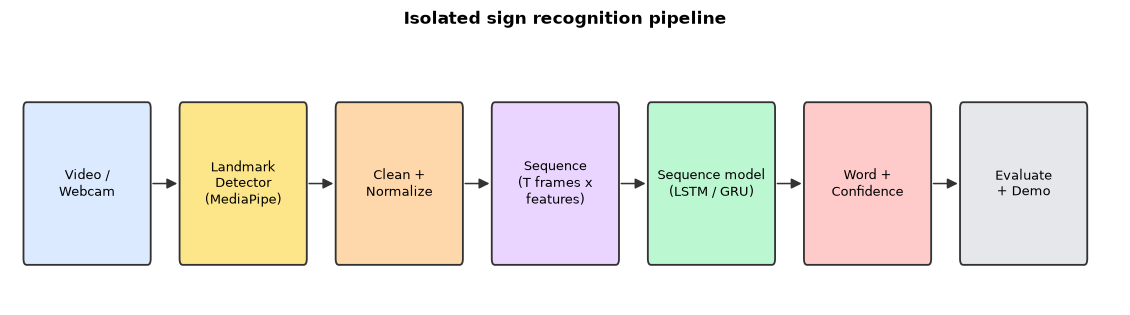

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

np.random.seed(0)
plt.rcParams["figure.dpi"] = 110

def draw_pipeline(steps, colors, title, figsize=(13, 3.2), per_row=None):
    fig, ax = plt.subplots(figsize=figsize)
    n = len(steps); w, h, gap = 1.55, 1.0, 0.45
    for i, (txt, col) in enumerate(zip(steps, colors)):
        x = i * (w + gap)
        ax.add_patch(FancyBboxPatch((x, 0), w, h, boxstyle="round,pad=0.04", fc=col, ec="#333", lw=1.2))
        ax.text(x + w/2, h/2, txt, ha="center", va="center", fontsize=8.5)
        if i < n - 1:
            ax.add_patch(FancyArrowPatch((x + w + 0.03, h/2), (x + w + gap - 0.03, h/2),
                                         arrowstyle="-|>", mutation_scale=14, color="#333"))
    ax.set_xlim(-0.2, n * (w + gap)); ax.set_ylim(-0.3, h + 0.5)
    ax.set_title(title, fontsize=11, weight="bold"); ax.axis("off"); plt.show()

steps = ["Video /\nWebcam", "Landmark\nDetector\n(MediaPipe)", "Clean +\nNormalize", "Sequence\n(T frames x\nfeatures)",
         "Sequence model\n(LSTM / GRU)", "Word +\nConfidence", "Evaluate\n+ Demo"]
colors = ["#dbeafe", "#fde68a", "#fed7aa", "#e9d5ff", "#bbf7d0", "#fecaca", "#e5e7eb"]
draw_pipeline(steps, colors, "Isolated sign recognition pipeline")

### อ่าน diagram ทีละกล่อง

1. **Video/Webcam** → ได้ภาพทีละเฟรม (แต่ละเฟรมคืออาร์เรย์ `H x W x 3` ของตัวเลข 0-255)
2. **Landmark Detector** → โมเดลสำเร็จรูป (เช่น MediaPipe Holistic) อ่านภาพแล้วบอกตำแหน่ง *จุดข้อต่อ* ของมือ ร่างกาย ใบหน้า **ขั้นนี้เราไม่ต้องฝึกเอง**
3. **Clean + Normalize** → จัดการเฟรมที่ตรวจไม่เจอ และทำให้พิกัดไม่ขึ้นกับว่าคนยืนตรงไหน ตัวใหญ่/เล็กแค่ไหน (ดูหัวข้อ 4)
4. **Sequence** → เรียงพิกัดของทุกเฟรมเป็นตาราง `T x D` (T = จำนวนเฟรม, D = จำนวนตัวเลขต่อเฟรม)
5. **LSTM/GRU** → โมเดลที่ *ฝึกเอง* อ่านลำดับแล้วตัดสินว่าเป็นคำไหน
6. **Word + Confidence** → ผลลัพธ์ เช่น `HELLO (0.92)`; ถ้า confidence ต่ำให้ขึ้น "ไม่แน่ใจ"
7. **Evaluate + Demo** → วัดผลด้วย accuracy / macro-F1 / confusion matrix แล้วทำเดโมกล้อง

**ทำไมแยก "ตรวจจับท่าทาง" ออกจาก "ตีความภาษามือ"?** เพราะเราไม่ต้องสอนโมเดลให้หามือในภาพเอง (งานยาก ต้องใช้ข้อมูลมหาศาล) แต่เอาโมเดลสำเร็จรูปมาทำ แล้วโฟกัสเวลาไปที่การแยกแยะ *การเคลื่อนไหว* ซึ่งเป็นหัวใจของภาษามือ ข้อดีอีกข้อคือโมเดลของเราเล็ก เร็ว และฝึกได้บนเครื่องธรรมดา

## 3. Landmarks: คอมพิวเตอร์ "เห็น" มือเป็นตัวเลข

MediaPipe Hand ให้ **21 จุดต่อมือหนึ่งข้าง** (จุด 0 = ข้อมือ, 1-4 = นิ้วโป้ง, 5-8 = นิ้วชี้, 9-12 = นิ้วกลาง, 13-16 = นิ้วนาง, 17-20 = นิ้วก้อย) แต่ละจุดมี `(x, y, z)`

เรายังไม่ได้ต่อกล้อง เลยสร้าง "มือจำลอง" ที่เรียงจุดตามรูปแบบเดียวกันเพื่อดูว่ามันหน้าตาเป็นอย่างไร

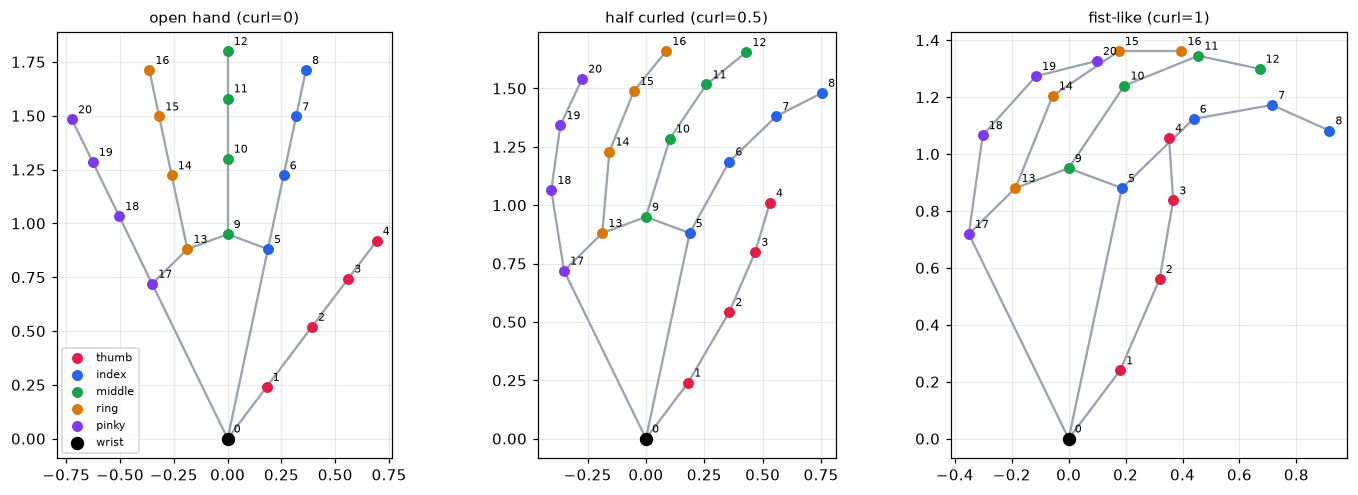

In [5]:
# ตำแหน่งเส้นเชื่อมระหว่างจุด (ตามผังมาตรฐาน 21 จุดของมือ)
HAND_CONNECTIONS = [(0,1),(1,2),(2,3),(3,4),
                    (0,5),(5,6),(6,7),(7,8),
                    (5,9),(9,10),(10,11),(11,12),
                    (9,13),(13,14),(14,15),(15,16),
                    (13,17),(17,18),(18,19),(19,20),(0,17)]
FINGER_COLORS = {"thumb": "#e11d48", "index": "#2563eb", "middle": "#16a34a", "ring": "#d97706", "pinky": "#7c3aed"}
FINGER_RANGES = {"thumb": range(1,5), "index": range(5,9), "middle": range(9,13), "ring": range(13,17), "pinky": range(17,21)}

def make_hand(curl=0.0, spread=1.0):
    # สร้างมือจำลอง 21 จุด (21,3). curl 0=เหยียดตรง, 1=กำ
    pts = np.zeros((21, 3))
    base_angles = {"thumb": 55, "index": 80, "middle": 92, "ring": 104, "pinky": 118}
    base_dist   = {"thumb": 0.35, "index": 0.9, "middle": 0.95, "ring": 0.9, "pinky": 0.8}
    seg_len = [0.35, 0.28, 0.22]
    for f, idxs in FINGER_RANGES.items():
        ang = np.deg2rad(90 + (base_angles[f] - 92) * spread)
        direction = np.array([np.cos(ang), np.sin(ang)])
        p = direction * base_dist[f] if f != "thumb" else np.array([np.cos(ang), np.sin(ang)]) * 0.3
        idxs = list(idxs)
        pts[idxs[0], :2] = p
        cur_angle = ang
        for k, j in enumerate(idxs[1:]):
            cur_angle -= curl * np.deg2rad(34) * (1 if f != "thumb" else -0.4)
            step = np.array([np.cos(cur_angle), np.sin(cur_angle)]) * seg_len[k]
            pts[j, :2] = pts[j-1, :2] + step
    pts[:, 2] = np.random.normal(0, 0.01, 21)   # z จำลอง
    return pts

def plot_hand(ax, pts, title="", annotate=True, color_by_finger=True):
    for a, b in HAND_CONNECTIONS:
        ax.plot(pts[[a,b],0], pts[[a,b],1], "-", color="#9ca3af", lw=1.5, zorder=1)
    for f, idxs in FINGER_RANGES.items():
        ax.scatter(pts[list(idxs),0], pts[list(idxs),1], s=38, color=FINGER_COLORS[f] if color_by_finger else "k", zorder=2, label=f)
    ax.scatter(*pts[0,:2], s=60, color="k", zorder=3, label="wrist")
    if annotate:
        for i in range(21): ax.annotate(str(i), pts[i,:2], textcoords="offset points", xytext=(4,4), fontsize=7)
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10); ax.grid(alpha=0.25)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (c, t) in zip(axes, [(0.0, "open hand (curl=0)"), (0.5, "half curled (curl=0.5)"), (1.0, "fist-like (curl=1)")]):
    plot_hand(ax, make_hand(curl=c), t)
axes[0].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()

### สิ่งที่ต้องสังเกต
- มือ 3 ท่า → **ตัวเลขชุดเดียวกันขนาดเดียวกัน (21 x 3)** แต่ค่าต่างกัน ตรงนี้คือหัวใจ: *ท่ามือ = ตำแหน่งของจุด*
- โมเดลไม่เคยเห็น "ภาพมือ" เลย มันเห็นแค่ตัวเลข 63 ตัวต่อเฟรม (21 x 3)

ลองดูตัวเลขจริง ๆ:

In [6]:
hand = make_hand(curl=0.0)
print("shape:", hand.shape, "= 21 จุด x (x, y, z)")
print("จุดที่ 0 (ข้อมือ)  :", hand[0].round(3))
print("จุดที่ 8 (ปลายนิ้วชี้):", hand[8].round(3))
print("flatten แล้วเป็น feature vector ยาว", hand.flatten().shape[0], "ตัวเลข")

# --- ขนาดข้อมูลต่อเฟรมของ MediaPipe Holistic ---
pose, face, hands = 33, 468, 21 * 2
print()
print("Holistic: pose", pose, "จุด | face", face, "จุด | hands", hands, "จุด -> รวม", pose + face + hands, "จุด")
print("ขนาด feature ต่อเฟรม (pose มี x,y,z,visibility / อื่น x,y,z):",
      pose*4 + face*3 + hands*3)

shape: (21, 3) = 21 จุด x (x, y, z)
จุดที่ 0 (ข้อมือ)  : [0.    0.    0.009]
จุดที่ 8 (ปลายนิ้วชี้): [0.364 1.712 0.023]
flatten แล้วเป็น feature vector ยาว 63 ตัวเลข

Holistic: pose 33 จุด | face 468 จุด | hands 42 จุด -> รวม 543 จุด
ขนาด feature ต่อเฟรม (pose มี x,y,z,visibility / อื่น x,y,z): 1662


> 🧪 **Mini challenge 3.1:** เปลี่ยน `curl` เป็น 0.8 แล้ววาดใหม่ นิ้วไหนงอก่อน? ลองเปลี่ยน `spread` เป็น 1.5 เกิดอะไรขึ้น?
>
> 🧪 **Mini challenge 3.2:** ถ้าเราสนใจแค่มือ (ไม่เอาใบหน้า) feature ต่อเฟรมจะเหลือกี่ตัว? (คำใบ้: 2 มือ x 21 จุด x 3)
>
> ❓ **คิดดู:** ภาษามือใช้ใบหน้า (สีหน้า, ตำแหน่งมือเทียบใบหน้า) ด้วย ทำไมโจทย์จึงบอกว่าไม่ควรจำกัดแค่ body pose?

## 4. Normalize: ทำไมต้องจัดพิกัดก่อนฝึก

MediaPipe ให้พิกัดแบบ *สัมพันธ์กับภาพ* ถ้าคนเดียวกันทำท่าเดิม แต่ **ยืนห่างกล้องต่างกัน** หรือ **ยืนคนละตำแหน่ง** ตัวเลขจะต่างกันหมด ทั้งที่ท่าเหมือนเดิม ทำให้โมเดลสับสน

วิธีที่นิยม: (1) ย้ายจุดอ้างอิง (เช่นข้อมือ) ไปที่ 0,0 → ไม่ขึ้นกับตำแหน่ง (2) หารด้วยความยาวอ้างอิง (เช่นระยะข้อมือถึงโคนนิ้วกลาง) → ไม่ขึ้นกับขนาด

In [ ]:
def normalize_hand(pts):
    # 1) translate: ข้อมือ (จุด 0) -> (0,0)   2) scale: หารด้วยระยะ ข้อมือ->โคนนิ้วกลาง (จุด 9)
    out = pts - pts[0]
    scale = np.linalg.norm(out[9, :2]) + 1e-8
    return out / scale

base = make_hand(curl=0.2)
person_A = base * 1.0 + np.array([0.0, 0.0, 0])      # ใกล้กล้อง อยู่ตรงกลาง
person_B = base * 0.45 + np.array([3.0, 2.0, 0])     # ไกลกล้อง (เล็กกว่า) อยู่มุมขวาบน

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for p, c, lab in [(person_A, "#2563eb", "A (near, center)"), (person_B, "#dc2626", "B (far, corner)")]:
    axes[0].scatter(p[:,0], p[:,1], s=22, color=c, label=lab)
    nh = normalize_hand(p); axes[1].scatter(nh[:,0], nh[:,1], s=22, color=c, alpha=0.6, label=lab)
axes[0].set_title("BEFORE normalize: same pose, very different numbers"); axes[1].set_title("AFTER normalize: they overlap")
for ax in axes: ax.set_aspect("equal"); ax.grid(alpha=0.25); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("ระยะห่างของตัวเลขก่อน normalize:", np.abs(person_A - person_B).mean().round(3))
print("ระยะห่างของตัวเลขหลัง normalize :", np.abs(normalize_hand(person_A) - normalize_hand(person_B)).mean().round(6))

### สิ่งที่ต้องสังเกต
ก่อน normalize จุดสองกลุ่มอยู่คนละที่ หลัง normalize ซ้อนกันสนิท → โมเดลจะเห็นว่า "ท่าเดียวกัน" ซึ่งเป็นสิ่งที่เราต้องการ

**เรื่องเฟรมที่ตรวจจับไม่ได้ (missing frames):** บางเฟรมมือถูกบัง/เบลอ detector จะไม่ส่งจุดมาให้ วิธีจัดการที่ใช้บ่อย: เติมด้วยศูนย์ (แล้วเพิ่ม flag บอกว่าหายไป), หรือ interpolate จากเฟรมข้างเคียง สิ่งสำคัญคือ **เลือกวิธีเดียวแล้วใช้ตรงกันทั้งตอนฝึกและตอนเดโม**

> 🧪 **Mini challenge 4.1:** เปลี่ยน `person_B` ให้ *หมุน* มือไป 30 องศา แล้ว normalize ซ้ำ ยังซ้อนกันไหม? ถ้าไม่ จะแก้อย่างไร (คำใบ้: การหมุนก็เป็น transform อีกแบบ)

## 5. Sequence: ทำไมต้องใช้ LSTM/GRU

คำภาษามือส่วนใหญ่ **คือการเคลื่อนไหวต่อเนื่อง ไม่ใช่ท่าเดียว** คำสองคำอาจใช้ท่ามือ *เหมือนกันทุกท่า* แต่ **ลำดับต่างกัน** (ขึ้น→ลง vs ลง→ขึ้น)

ทดลอง: สร้างวิถีการเคลื่อนที่ของข้อมือ 2 แบบที่ใช้ตำแหน่งชุดเดียวกัน แต่สลับลำดับ

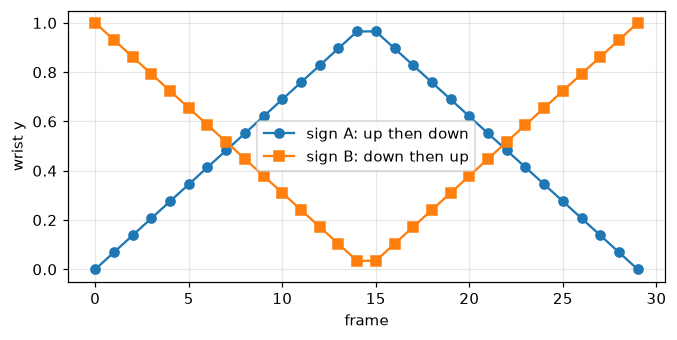

ค่าเฉลี่ยตลอดคลิป  A: 0.483 | B: 0.517
-> ถ้ารวมทุกเฟรมเป็นค่าเฉลี่ย (ทิ้งลำดับ) สองคำนี้ 'เหมือนกันเกือบเป๊ะ' แยกไม่ได้


In [7]:
T = 30
t = np.linspace(0, 1, T)
up_then_down = np.where(t < 0.5, t * 2, 2 - t * 2)          # y: 0 -> 1 -> 0
down_then_up = 1 - up_then_down                               # y: 1 -> 0 -> 1

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(up_then_down, "o-", label="sign A: up then down"); ax.plot(down_then_up, "s-", label="sign B: down then up")
ax.set_xlabel("frame"); ax.set_ylabel("wrist y"); ax.legend(); ax.grid(alpha=0.3); plt.show()

print("ค่าเฉลี่ยตลอดคลิป  A:", up_then_down.mean().round(3), "| B:", down_then_up.mean().round(3))
print("-> ถ้ารวมทุกเฟรมเป็นค่าเฉลี่ย (ทิ้งลำดับ) สองคำนี้ 'เหมือนกันเกือบเป๊ะ' แยกไม่ได้")

ถ้าโมเดลเอาแต่ละเฟรมมาดูแยกกัน หรือเอามาเฉลี่ย มันจะแยกสองคำนี้ไม่ได้ **RNN (รวม LSTM/GRU)** แก้ปัญหานี้ด้วยการมี "ความจำ" (hidden state `h`) ที่อัปเดตทีละเฟรม:

```
h_t = f( h_(t-1) , x_t )      # ความจำใหม่ = ฟังก์ชันของ (ความจำเดิม, ข้อมูลเฟรมนี้)
```

ลองสร้าง RNN จิ๋วด้วย NumPy (น้ำหนักสุ่ม ยังไม่ฝึก) แล้วดูว่า `h` สุดท้ายของสองลำดับต่างกันไหม

In [8]:
rng = np.random.default_rng(1)
H = 4                                        # ขนาดความจำ
W_h = rng.normal(0, 0.9, (H, H)); W_x = rng.normal(0, 1.2, (H, 1)); b = np.zeros(H)

def run_rnn(seq):
    h = np.zeros(H)
    for x_t in seq:                          # ไล่ทีละเฟรม ตามลำดับเวลา
        h = np.tanh(W_h @ h + W_x[:, 0] * x_t + b)
    return h

hA, hB = run_rnn(up_then_down), run_rnn(down_then_up)
print("final h (A):", hA.round(3))
print("final h (B):", hB.round(3))
print("ต่างกันไหม? ความต่างเฉลี่ย =", np.abs(hA - hB).mean().round(3))

# เปรียบเทียบ: ถ้าเอาเฟรมมาเรียงสลับแบบสุ่ม (ทำลายลำดับ) ผลของ RNN เปลี่ยน
shuffled = rng.permutation(up_then_down)
print("เปลี่ยนลำดับเฟรมของ A แบบสุ่ม -> h เปลี่ยน:", np.abs(run_rnn(shuffled) - hA).mean().round(3))

final h (A): [-0.918 -0.424 -0.011  0.816]
final h (B): [-0.944 -0.487 -0.758  0.815]
ต่างกันไหม? ความต่างเฉลี่ย = 0.209
เปลี่ยนลำดับเฟรมของ A แบบสุ่ม -> h เปลี่ยน: 0.164


### สิ่งที่ต้องสังเกต
- `h` สุดท้ายของ A กับ B **ต่างกัน** ทั้งที่ค่าเฉลี่ยเท่ากัน → RNN "รู้" ว่าลำดับต่างกัน
- สลับลำดับเฟรม ผลก็เปลี่ยน → โมเดลแบบนี้ไวต่อลำดับ
- ตอนนี้น้ำหนัก *สุ่ม* ยังไม่ได้เรียนรู้อะไร การ *ฝึก* คือการปรับน้ำหนักให้ `h` สุดท้ายนำไปสู่คำตอบที่ถูก (notebook 04)

**LSTM/GRU** คือ RNN รุ่นปรับปรุงที่มี "ประตู" (gate) ควบคุมว่าจะจำอะไร/ลืมอะไร ทำให้จำลำดับยาวได้ดีกว่า RNN ธรรมดา ซึ่งมักลืมต้นลำดับ (รายละเอียดอยู่ช่วงที่ 6)

> ❓ **คิดดู:** ถ้าเราตัดคลิปให้ทุกคำยาว 30 เฟรมเท่ากัน คำที่ทำเร็วกับช้าจะเป็นอย่างไร? (เรื่อง padding / resampling จะเจอตอน hands-on)

## 6. Data leakage: ทำไมต้องแบ่ง train/val/test *ตามผู้แสดง*

โจทย์เขียนว่า "แบ่ง train / validation / test ตามผู้แสดงภาษามือ เพื่อทดสอบกับคนที่โมเดลไม่เคยเห็น"

ถ้าสุ่มแบ่งคลิป โดยคนเดียวกันอยู่ทั้ง train และ test โมเดลอาจแค่ **จำสไตล์ของคนคนนั้น** แล้วได้คะแนนสวย แต่พอเจอคนใหม่ก็พัง นี่คือ *data leakage* ทดลองด้วยข้อมูลสังเคราะห์: แต่ละคำมี "รูปแบบจริง" แต่แต่ละคนมี "นิสัยส่วนตัว" (offset) ติดมาด้วย

> ⚠️ ข้อมูลนี้ **สังเคราะห์เพื่อสาธิตแนวคิด** ตัวเลขจริงขึ้นกับชุดข้อมูล แต่ทิศทางของปรากฏการณ์เป็นแบบนี้จริง

ข้อมูล: (480, 20) | คำ: 5 | ผู้แสดง: 8


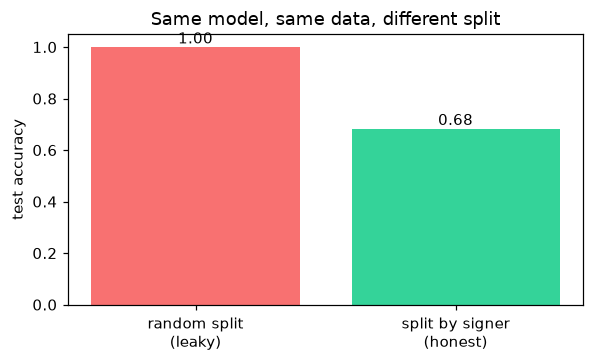

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

rng = np.random.default_rng(7)
n_words, n_signers, reps, dim = 5, 8, 12, 20
word_pattern = rng.normal(0, 1.0, (n_words, dim))        # "ความหมายจริง" ของแต่ละคำ
signer_style = rng.normal(0, 1.6, (n_signers, dim))      # นิสัยส่วนตัวของแต่ละคน (ใหญ่กว่า pattern)

X, y, who = [], [], []
for s in range(n_signers):
    for w in range(n_words):
        for _ in range(reps):
            X.append(word_pattern[w] + signer_style[s] + rng.normal(0, 0.3, dim)); y.append(w); who.append(s)
X, y, who = np.array(X), np.array(y), np.array(who)
print("ข้อมูล:", X.shape, "| คำ:", n_words, "| ผู้แสดง:", n_signers)

# (A) สุ่มแบ่ง -> คนเดียวกันอยู่ทั้ง train และ test (LEAK)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
acc_random = accuracy_score(yte, KNeighborsClassifier(1).fit(Xtr, ytr).predict(Xte))

# (B) แบ่งตามคน -> test เป็นคนที่โมเดลไม่เคยเห็น
test_people = [6, 7]
tr, te = ~np.isin(who, test_people), np.isin(who, test_people)
acc_signer = accuracy_score(y[te], KNeighborsClassifier(1).fit(X[tr], y[tr]).predict(X[te]))

fig, ax = plt.subplots(figsize=(5.5, 3.4))
bars = ax.bar(["random split\n(leaky)", "split by signer\n(honest)"], [acc_random, acc_signer], color=["#f87171", "#34d399"])
ax.set_ylim(0, 1.05); ax.set_ylabel("test accuracy"); ax.bar_label(bars, fmt="%.2f"); ax.set_title("Same model, same data, different split")
plt.tight_layout(); plt.show()

### สิ่งที่ต้องสังเกต
โมเดลและข้อมูลเดิมทุกอย่าง แค่เปลี่ยนวิธีแบ่ง คะแนนต่างกันมาก แบบ "สุ่มแบ่ง" ให้ภาพที่ **สวยเกินจริง** เพราะ test มีคนที่โมเดลเคยเห็นแล้ว ตอนไปเดโมกับคนใหม่ผลจะใกล้เคียงแบบที่สอง

กฎที่ต้องจำ: **ทุกอย่างที่ "เหมือนกันแต่ไม่ใช่สิ่งที่เราอยากสอน" (คน, วิดีโอเดียวกัน, ห้องเดียวกัน) ต้องอยู่ฝั่งเดียวกันของการแบ่ง** ใน sklearn ทำได้ด้วย `GroupShuffleSplit` / `GroupKFold`

> 🧪 **Mini challenge 6.1:** เพิ่ม `n_signers` เป็น 30 แล้วรันใหม่ ช่องว่างระหว่างสองแบบเล็กลงไหม? ทำไม?
>
> 🧪 **Mini challenge 6.2:** ลองเปลี่ยน `signer_style` จาก `1.6` เป็น `0.2` แล้วดูผล (นิสัยส่วนตัวน้อย leak ก็เบา)

## 7. ศัพท์ที่ต้องรู้ + สิ่งที่ต้องยืนยันก่อนเริ่ม

| ศัพท์ | ความหมายสั้นๆ |
|---|---|
| **Landmark / Keypoint** | จุดบนร่างกาย (ข้อมือ, ปลายนิ้ว ฯลฯ) ที่ detector ระบุตำแหน่งให้ |
| **Frame** | ภาพนิ่งหนึ่งภาพในวิดีโอ |
| **Feature vector** | ตัวเลขชุดหนึ่งที่เป็น "คำอธิบาย" ข้อมูลหนึ่งชิ้นสำหรับโมเดล |
| **Isolated sign recognition** | รู้จำทีละคำ (ต่างจากแปลประโยคต่อเนื่อง) |
| **Baseline** | โมเดลง่ายๆ ตัวแรกไว้เป็นเส้นเทียบ ก่อนลองของซับซ้อน |
| **Data leakage** | ข้อมูลทดสอบ "รั่ว" เข้ามาในการฝึก ทำให้คะแนนสูงเกินจริง |
| **Confidence** | ความมั่นใจของโมเดลต่อคำตอบ (ใช้ตัดสินว่า "ไม่แน่ใจ") |

### สิ่งที่ต้องยืนยันก่อนเริ่มโปรเจกต์ (จากเอกสารโจทย์)
- [ ] ภาษามือเป้าหมาย: **ไทยหรือ ASL** และชุดคำที่ต้องการ
- [ ] แหล่งข้อมูล สิทธิ์ใช้งาน ความยินยอมของผู้ร่วมบันทึก และอุปกรณ์ทดสอบ
- [ ] ถ้าเลือกภาษามือไทย ต้องใช้ชุดข้อมูลภาษามือไทย — WLASL และ ASL Citizen เป็น **ข้อมูลอ้างอิงของ ASL** ไม่ใช่ชุดข้อมูลสำหรับภาษามือไทยโดยอัตโนมัติ

## 8. Resources สำหรับ notebook นี้

**ในเอกสารโจทย์** (ค้นด้วยชื่อ): *MediaPipe Holistic Landmarker API*, *ASL Citizen — Dataset Description*, *WLASL — Research Paper*

**แนะนำเพิ่ม (ค้นยืนยันแล้วว่ามีอยู่):**
- 3Blue1Brown — Neural Networks (วิดีโอ + บทความ): https://3blue1brown.com/neural-networks
- Google Machine Learning Crash Course: https://developers.google.com/machine-learning/crash-course
- Python Data Science Handbook (ฟรี เป็น notebook): https://github.com/jakevdp/PythonDataScienceHandbook
- ก่อนจะลงมือต่อกล้อง ลองอ่านหน้า MediaPipe Holistic Landmarker และดูว่าให้จุดอะไรกลับมาบ้าง

> ⏭️ **ต่อไป:** `02_ml_basics.ipynb` — พื้นฐาน ML: train/val/test, overfit, โมเดลคลาสสิก